In [1]:
from pyspark.sql.types import *
from pyspark.sql import SparkSession
from pyspark.sql.functions import *

In [2]:
spark = (SparkSession
       .builder
       .appName("DF SF Fire Example")
       .getOrCreate())

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/amit/spark-install/spark/python/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/07 21:00:23 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/07 21:00:24 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


# Reading structured data using a schema 

Spark can infer the schema but that can be costly. Spark can also infer schema from a sample at a lesser cost. Here we will define the schema explicitly. Note that we changed column names to not have space in them as that can be problematic when saving data.

In [3]:
fire_schema =  StructType([StructField('CallNumber', IntegerType(), True),
                           StructField('UnitID', StringType(), True),
                           StructField('IncidentNumber', IntegerType(), True),
                           StructField('CallType', StringType(), True),
                           StructField('CallDate', StringType(), True),
                           StructField('WatchDate', StringType(), True),
                           StructField('ReceivedDtTm', StringType(), True),
                           StructField('EntryDtTm', StringType(), True),
                           StructField('DispatchDtTm', StringType(), True),
                           StructField('ResponseDtTm', StringType(), True),
                           StructField('OnSceneDtTm', StringType(), True),
                           StructField('TransportDtTm', StringType(), True),
                           StructField('HospitalDtTm', StringType(), True),
                           StructField('CallFinalDisposition', StringType(), True),
                           StructField('AvailableDtTm', StringType(), True),
                           StructField('Address', StringType(), True),
                           StructField('City', StringType(), True),
                           StructField('Zipcode', DoubleType(), True),
                           StructField('Battalion', StringType(), True),
                           StructField('StationArea', StringType(), True),
                           StructField('Box', StringType(), True),
                           StructField('OriginalPriority', StringType(), True),
                           StructField('Priority', StringType(), True),
                           StructField('FinalPriority', IntegerType(), True),
                           StructField('ALSUnit', BooleanType(), True),
                           StructField('CallTypeGroup', StringType(), True),
                           StructField('NumAlarms', IntegerType(), True),
                           StructField('UnitType', StringType(), True),
                           StructField('UnitSequenceInCallDispatch', IntegerType(), True),
                           StructField('FirePreventionDistrict', StringType(), True),
                           StructField('SupervisorDistrict', StringType(), True),
                           StructField('Neighborhood', StringType(), True),
                           StructField('RowID', StringType(), True),
                           StructField('Location', StringType(), True),
                           StructField('DataAsOf', StringType(), True),
                           StructField('DataLoadedAt', StringType(), True)])

In [4]:
sf_fire_file = "hdfs:///user/amit/data/SF-Fire-Calls-20261007-100th.csv"
timestamp_format = "yyyy MMM dd hh:mm:ss a"

fire_df = (spark.read.csv(sf_fire_file, header=True, schema=fire_schema)
           .withColumn("Zipcode", col("Zipcode").cast("int"))
           .withColumn("Delay", (unix_timestamp("OnSceneDtTm", timestamp_format)
                                            - unix_timestamp("ReceivedDtTm", timestamp_format)) / 60))

# Projections and Filters

A *projection* in relational parlance is a way to return only certain columns, while a *filter* returns only the rows matching a certain relational condition. In Spark, projections are done with the `select()` method, while filters can be expressed using the `filter()` or `where()` methods.

In [5]:
few_fire_df = (fire_df.select("IncidentNumber", "AvailableDtTm", "CallType")
                .where(col("CallType") != "Medical Incident"))

In [6]:
few_fire_df.show(5,False)

+--------------+-----------------------+----------------------------------+
|IncidentNumber|AvailableDtTm          |CallType                          |
+--------------+-----------------------+----------------------------------+
|16038974      |2016 Apr 07 03:13:13 PM|Alarms                            |
|16040842      |2016 Apr 12 09:31:58 AM|Alarms                            |
|16038076      |2016 Apr 05 04:03:13 PM|Traffic Collision                 |
|16038985      |2016 Apr 07 03:39:26 PM|Traffic Collision                 |
|16040632      |2016 Apr 11 06:36:27 PM|Structure Fire / Smoke in Building|
+--------------+-----------------------+----------------------------------+
only showing top 5 rows


26/11/07 21:00:30 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: Incident Number, Call Type, Available DtTm
 Schema: IncidentNumber, CallType, AvailableDtTm
Expected: IncidentNumber but found: Incident Number
CSV file: hdfs://cscluster00.boisestate.edu:9000/user/amit/data/SF-Fire-Calls-20261007-100th.csv


What if we want to know how many distinct `CallTypes` were recorded as the causes of fire calls?

In [7]:
(fire_df
 .select("CallType")
 .where(col("CallType").isNotNull())
 .agg(count_distinct("CallType").alias("DistinctCallTypes"))
 .show(truncate=False))
      

26/11/07 21:00:31 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: Call Type
 Schema: CallType
Expected: CallType but found: Call Type
CSV file: hdfs://cscluster00.boisestate.edu:9000/user/amit/data/SF-Fire-Calls-20261007-100th.csv


+-----------------+
|DistinctCallTypes|
+-----------------+
|31               |
+-----------------+



We can list the distinct call types in the data set using the following query.

In [8]:
(fire_df
 .select("CallType")
 .where(col("CallType").isNotNull())
 .distinct()
 .show(truncate=False))

26/11/07 21:00:32 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: Call Type
 Schema: CallType
Expected: CallType but found: Call Type
CSV file: hdfs://cscluster00.boisestate.edu:9000/user/amit/data/SF-Fire-Calls-20261007-100th.csv


+--------------------------------------------+
|CallType                                    |
+--------------------------------------------+
|Elevator / Escalator Rescue                 |
|Marine Fire                                 |
|Structure Fire / Smoke in Building          |
|Alarms                                      |
|Odor (Strange / Unknown)                    |
|Citizen Assist / Service Call               |
|HazMat                                      |
|Watercraft in Distress                      |
|Explosion                                   |
|Oil Spill                                   |
|Vehicle Fire                                |
|Train / Rail Fire                           |
|Extrication / Entrapped (Machinery, Vehicle)|
|Other                                       |
|Outside Fire                                |
|Traffic Collision                           |
|Assist Police                               |
|Gas Leak (Natural and LP Gases)             |
|Water Rescue

# Renaming, Adding, and Dropping Columns

We can rename columns for reasons of convention, or sometimes for readability or brevity. Let's change the name of our `Delayed` column to `ResponseDelayedinMins` and take a look at response times that were longer than five minutes.

In [9]:
fire_df.cache()
fire_df.count()

26/11/07 21:00:32 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/11/07 21:00:33 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: Call Number, Unit ID, Incident Number, Call Type, Call Date, Watch Date, Received DtTm, Entry DtTm, Dispatch DtTm, Response DtTm, On Scene DtTm, Transport DtTm, Hospital DtTm, Call Final Disposition, Available DtTm, Address, City, Zipcode of Incident, Battalion, Station Area, Box, Original Priority, Priority, Final Priority, ALS Unit, Call Type Group, Number of Alarms, Unit Type, Unit sequence in call dispatch, Fire Prevention District, Supervisor District, Neighborhooods - Analysis Boundaries, RowID, case_location, data_as_of, data_loaded_at
 Schema: CallNumber, UnitID, IncidentNumber, CallType, CallDate, WatchDate, ReceivedDtTm, EntryDtTm, DispatchDtTm, ResponseDtTm, OnSceneDtTm, TransportDtTm, HospitalDtTm

74579

In [10]:
new_fire_df = fire_df.withColumnRenamed("Delay", "ResponseDelayedinMins")

In [11]:
(new_fire_df
 .select("ResponseDelayedinMins")
 .where(col("ResponseDelayedinMins") > 5)
 .show(5, False))

+---------------------+
|ResponseDelayedinMins|
+---------------------+
|20.35                |
|6.366666666666666    |
|7.083333333333333    |
|6.4                  |
|15.45                |
+---------------------+
only showing top 5 rows


Modifying the contents of a column or its type are common operations during data exploration. In some cases, the data is raw or dirty or its types are not amenable to being supplied as arguments to relational operators. More complex date and time manipulations.

In [12]:
fire_ts_df = (new_fire_df
              .withColumn("IncidentDate", to_timestamp(col("CallDate"), "MM/dd/yyyy"))
              .drop("CallDate")
              .withColumn("OnWatchDate", to_timestamp(col("WatchDate"), "MM/dd/yyyy"))
              .drop("WatchDate")
              .withColumn("AvailableDtTS", to_timestamp(col("AvailableDtTm"), timestamp_format))
              .drop("AvailableDtTm"))
              

In [13]:
(fire_ts_df
 .select("IncidentDate", "OnWatchDate", "AvailableDtTS")
         .show(5, False))

+-------------------+-------------------+-------------------+
|IncidentDate       |OnWatchDate        |AvailableDtTS      |
+-------------------+-------------------+-------------------+
|2016-04-08 00:00:00|2016-04-08 00:00:00|2016-04-08 13:59:43|
|2016-04-05 00:00:00|2016-04-05 00:00:00|2016-04-05 16:58:30|
|2016-04-12 00:00:00|2016-04-12 00:00:00|2016-04-12 10:22:41|
|2016-04-03 00:00:00|2016-04-03 00:00:00|2016-04-03 21:54:28|
|2016-04-12 00:00:00|2016-04-12 00:00:00|2016-04-12 23:54:28|
+-------------------+-------------------+-------------------+
only showing top 5 rows


Now we can query using functions from `spark.sql.functions` like `dayofmonth(), dayofyear, dayofweek()` to explore. For example, we could find out how many calls were logged in the last seven days, or we could see how many years' worth of calls are included in the data set.

In [14]:
(fire_ts_df
  .select(year('IncidentDate'))
 .distinct()
 .orderBy(year('IncidentDate'))
 .show(30))

+------------------+
|year(IncidentDate)|
+------------------+
|              2000|
|              2001|
|              2002|
|              2003|
|              2004|
|              2005|
|              2006|
|              2007|
|              2008|
|              2009|
|              2010|
|              2011|
|              2012|
|              2013|
|              2014|
|              2015|
|              2016|
|              2017|
|              2018|
|              2019|
|              2020|
|              2021|
|              2022|
|              2023|
|              2024|
|              2025|
|              2026|
+------------------+



# Aggregations

What if we want to know what the most common types of fire calls were, or what zip codes accounted for the most calls?

A handful of transformations and actions on DataFrames such as `groupBy()`, `orderBy()`, and `count()`, offer the ability to aggregate by column names and then aggregate counts across them.

In [15]:
(fire_ts_df
 .select("callType")
 .where(col("CallType").isNotNull())
 .groupBy("callType")
 .count()
 .orderBy("count", ascending=False)
 .show(truncate=False))

+----------------------------------+-----+
|callType                          |count|
+----------------------------------+-----+
|Medical Incident                  |49278|
|Alarms                            |8816 |
|Structure Fire / Smoke in Building|7802 |
|Traffic Collision                 |2967 |
|Other                             |1276 |
|Citizen Assist / Service Call     |1165 |
|Outside Fire                      |1047 |
|Gas Leak (Natural and LP Gases)   |389  |
|Water Rescue                      |381  |
|Vehicle Fire                      |330  |
|Electrical Hazard                 |273  |
|Elevator / Escalator Rescue       |239  |
|Smoke Investigation (Outside)     |169  |
|Odor (Strange / Unknown)          |136  |
|Fuel Spill                        |77   |
|HazMat                            |42   |
|Industrial Accidents              |38   |
|Train / Rail Incident             |27   |
|Explosion                         |26   |
|Assist Police                     |14   |
+----------

DataFrames also provide common statistical functions such as `min(), max(), sum()`, and `avg()`. Here is an example. 

In [16]:
import pyspark.sql.functions as F

In [17]:
(fire_ts_df
 .select(F.sum("NumAlarms"), F.avg("ResponseDelayedinMins"),
         F.min("ResponseDelayedinMins"), F.max("ResponseDelayedinMins"))
 .show())

+--------------+--------------------------+--------------------------+--------------------------+
|sum(NumAlarms)|avg(ResponseDelayedinMins)|min(ResponseDelayedinMins)|max(ResponseDelayedinMins)|
+--------------+--------------------------+--------------------------+--------------------------+
|         74913|         9.473835143990346|       -249.66666666666666|                   1146.65|
+--------------+--------------------------+--------------------------+--------------------------+



# Further Data Explorations

 1. What were all the different types of fire calls in 2025?
 2. What months within the year 2025 saw the highest number of fire calls?
 3. Which neighborhood in San Francisco generated the most fire calls in 2025?
 4. Which neighborhoods had the worst response times to fire calls in 2025?
 5. Which week in 2025 had the most fire calls?
 6. Is there a correlation between neighborhood, zip code, and number of fire calls?

In [18]:
fire_2025_df = fire_ts_df.where(year("IncidentDate") == 2025).cache()

### Q1. What were all the different types of fire calls in 2025?

In [19]:
(fire_2025_df
 .where(col("CallType").isNotNull())
 .select("CallType")
 .distinct()
 .show(50, truncate=False))

+--------------------------------------------+
|CallType                                    |
+--------------------------------------------+
|Alarms                                      |
|Vehicle Fire                                |
|Outside Fire                                |
|Medical Incident                            |
|Structure Fire / Smoke in Building          |
|Other                                       |
|Traffic Collision                           |
|Water Rescue                                |
|Fuel Spill                                  |
|Elevator / Escalator Rescue                 |
|Confined Space / Structure Collapse         |
|Administrative                              |
|Odor (Strange / Unknown)                    |
|Citizen Assist / Service Call               |
|Extrication / Entrapped (Machinery, Vehicle)|
|Gas Leak (Natural and LP Gases)             |
|Electrical Hazard                           |
|Smoke Investigation (Outside)               |
|Watercraft i

### Q2. What months within the year 2025 saw the highest number of fire calls?

In [20]:
(fire_2025_df
 .withColumn("Month", month("IncidentDate"))
 .groupBy("Month")
 .agg(count_distinct("CallNumber").alias("Calls"))
 .orderBy("Calls", ascending=False)
 .show())

+-----+-----+
|Month|Calls|
+-----+-----+
|    1|  333|
|   12|  322|
|   10|  319|
|    8|  308|
|    2|  307|
|    5|  306|
|    9|  304|
|    3|  303|
|   11|  298|
|    4|  297|
|    7|  292|
|    6|  289|
+-----+-----+



### Q3. Which neighborhood in San Francisco generated the most fire calls in 2025?

In [21]:
(fire_2025_df
 .where(col("Neighborhood") != "None")
 .groupBy("Neighborhood")
 .agg(count_distinct("CallNumber").alias("Calls"))
 .orderBy("Calls", ascending=False)
 .show(truncate=False))

+------------------------------+-----+
|Neighborhood                  |Calls|
+------------------------------+-----+
|Tenderloin                    |532  |
|South of Market               |445  |
|Mission                       |344  |
|Financial District/South Beach|212  |
|Bayview Hunters Point         |189  |
|Western Addition              |138  |
|Nob Hill                      |131  |
|Sunset/Parkside               |131  |
|Hayes Valley                  |125  |
|Outer Richmond                |93   |
|Mission Bay                   |82   |
|Castro/Upper Market           |77   |
|Marina                        |75   |
|West of Twin Peaks            |75   |
|Chinatown                     |69   |
|Excelsior                     |66   |
|Bernal Heights                |65   |
|Russian Hill                  |62   |
|Pacific Heights               |62   |
|Inner Sunset                  |59   |
+------------------------------+-----+
only showing top 20 rows


### Q4. Which neighborhoods had the worst response times to fire calls in 2025?

In [22]:
(fire_2025_df
 .where((col("ResponseDelayedinMins") >= 0) & (col("Neighborhood") != "None"))
 .groupBy("Neighborhood")
 .agg(round(avg("ResponseDelayedinMins"), 2).alias("AvgDelayMins"), 
      round(median("ResponseDelayedinMins"), 2).alias("MedianDelayMins"))
 .orderBy("AvgDelayMins", ascending=False)
 .show(truncate=False))

+------------------------------+------------+---------------+
|Neighborhood                  |AvgDelayMins|MedianDelayMins|
+------------------------------+------------+---------------+
|Glen Park                     |21.75       |8.55           |
|South of Market               |18.02       |8.5            |
|Lincoln Park                  |17.94       |9.58           |
|Marina                        |16.81       |9.48           |
|Potrero Hill                  |15.97       |9.72           |
|Outer Richmond                |14.15       |8.4            |
|Inner Richmond                |14.15       |8.57           |
|Financial District/South Beach|14.13       |9.08           |
|West of Twin Peaks            |13.87       |8.87           |
|Visitacion Valley             |13.49       |8.73           |
|Outer Mission                 |13.27       |10.91          |
|Treasure Island               |13.17       |7.28           |
|Bernal Heights                |12.64       |9.65           |
|Lakesho

### Q5. Which week in 2025 had the most fire calls?

In [23]:
(fire_2025_df
 .withColumn("Week", to_date(date_trunc("week", "IncidentDate")))
 .groupBy("Week")
 .agg(count_distinct("CallNumber").alias("Calls"))
 .orderBy("Calls", ascending=False)
 .show())

+----------+-----+
|      Week|Calls|
+----------+-----+
|2025-02-03|   84|
|2025-12-15|   82|
|2025-10-13|   80|
|2025-02-10|   78|
|2025-01-13|   77|
|2025-03-24|   76|
|2025-09-22|   76|
|2025-01-27|   75|
|2025-11-03|   74|
|2025-03-31|   74|
|2025-02-17|   74|
|2025-01-20|   74|
|2025-09-15|   74|
|2025-12-01|   73|
|2025-01-06|   73|
|2025-04-28|   72|
|2025-10-27|   72|
|2025-08-04|   72|
|2025-09-29|   71|
|2025-12-08|   71|
+----------+-----+
only showing top 20 rows


### Q6. Is there a correlation between neighborhood, zip code, and number of fire calls?
I interpreted this question as: "Are the calls from a given neighborhood usually concentrated in a single zip code? In other words, when a call comes in from a given neighborhood, can we usually assume it is from that zip code?"

In [24]:
pair_df = (fire_2025_df
           .where(col("Zipcode").isNotNull() & (col("Neighborhood") != "None"))
           .groupBy("Neighborhood", "Zipcode")
           .agg(count_distinct("CallNumber").alias("Calls")))

pair_df.orderBy("Calls", ascending=False).show(truncate=False)

+------------------------------+-------+-----+
|Neighborhood                  |Zipcode|Calls|
+------------------------------+-------+-----+
|South of Market               |94103  |387  |
|Tenderloin                    |94102  |354  |
|Mission                       |94110  |196  |
|Bayview Hunters Point         |94124  |178  |
|Tenderloin                    |94109  |174  |
|Mission                       |94103  |148  |
|Financial District/South Beach|94105  |97   |
|Hayes Valley                  |94102  |89   |
|Nob Hill                      |94109  |88   |
|Outer Richmond                |94121  |79   |
|Marina                        |94123  |72   |
|Castro/Upper Market           |94114  |68   |
|Sunset/Parkside               |94122  |65   |
|Bernal Heights                |94110  |64   |
|Lakeshore                     |94132  |58   |
|Western Addition              |94115  |57   |
|North Beach                   |94133  |55   |
|Sunset/Parkside               |94116  |54   |
|Mission Bay 

The zip codes with the most calls are shown below.

/home/amit/spark-install/spark/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


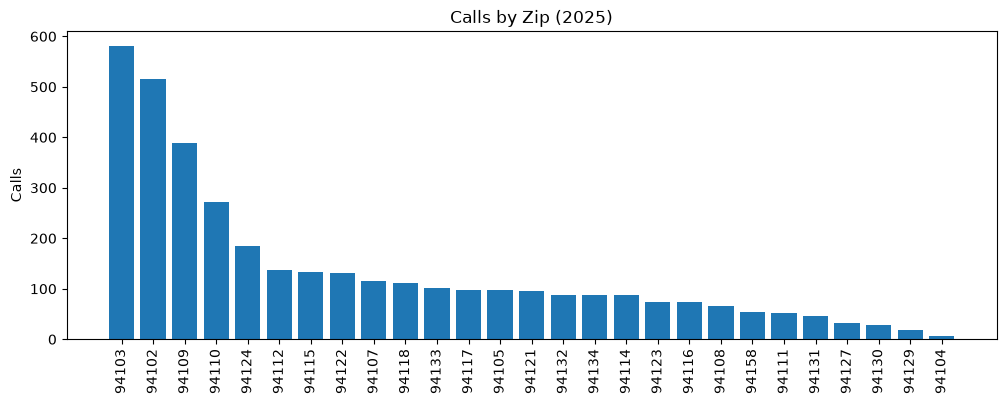

In [25]:
import matplotlib.pyplot as plt

zip_pdf = (pair_df.groupBy("Zipcode")
           .agg(F.sum("Calls").alias("Calls"))
           .orderBy(F.desc("Calls"))
           .toPandas())

plt.figure(figsize=(12, 4))
plt.bar(zip_pdf["Zipcode"].astype(str), zip_pdf["Calls"])
plt.xticks(rotation=90); plt.ylabel("Calls"); plt.title("Calls by Zip (2025)")
plt.show()

The heatmap below shows which zip codes the calls from each neighborhood came from.
- Rows: neighborhoods (~41)
- Columns: zip codes (~27)
- Cell color: share of that neighborhood's calls that came from the zip code. Darker means a higher share.

In [26]:
# Share of calls whose zip matches the neighborhood's most common (representative) zip
pair_pdf = (pair_df.toPandas()
               .pivot(index="Neighborhood", columns="Zipcode", values="Calls")
               .fillna(0))

overall = pair_pdf.max(axis=1).sum() / pair_pdf.values.sum()
print(f"Calls in their neighborhood's top zip: {overall:.1%}")

/home/amit/spark-install/spark/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Calls in their neighborhood's top zip: 71.8%


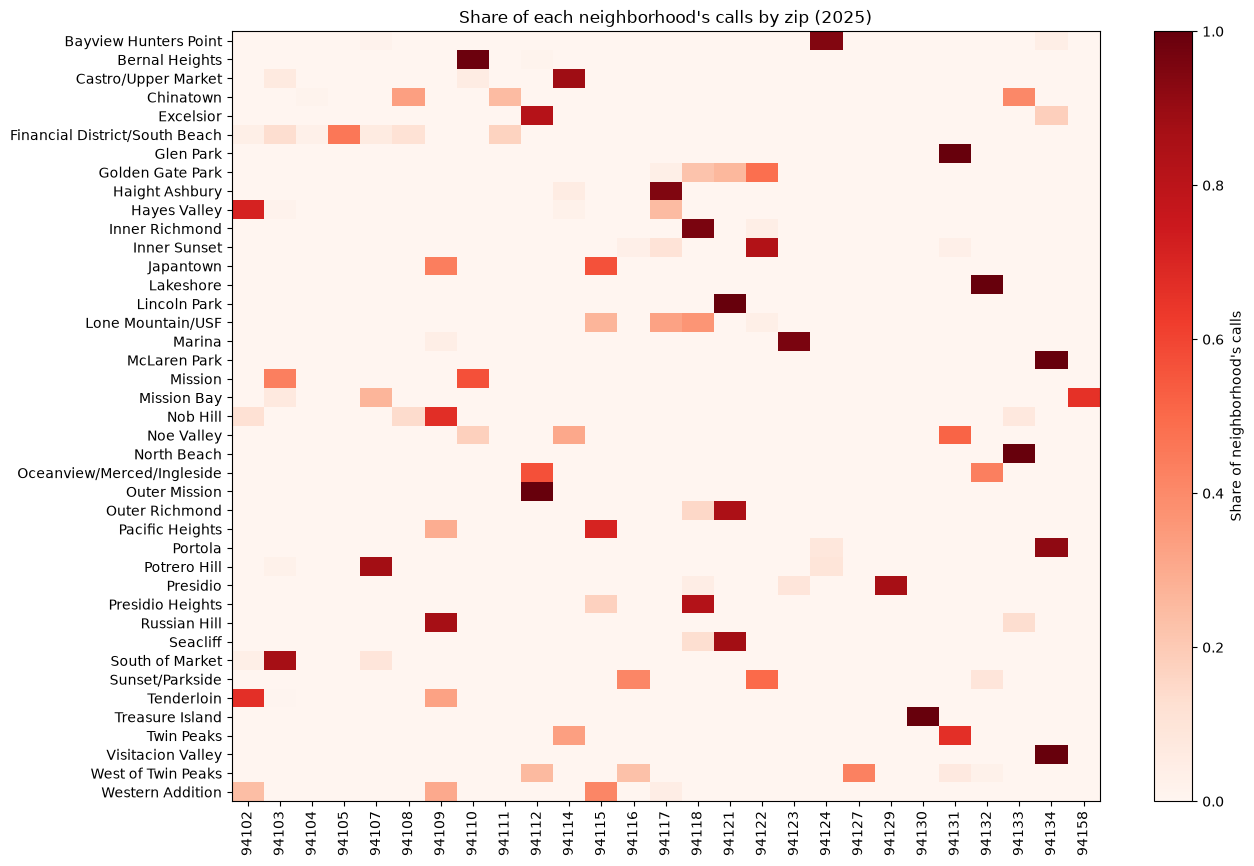

In [27]:
row_share = pair_pdf.div(pair_pdf.sum(axis=1), axis=0)
plt.figure(figsize=(14, 10))
plt.imshow(row_share, aspect="auto", cmap="Reds", vmin=0, vmax=1)
plt.xticks(range(len(row_share.columns)), row_share.columns.astype(str), rotation=90)
plt.yticks(range(len(row_share.index)), row_share.index)
plt.colorbar(label="Share of neighborhood's calls")
plt.title("Share of each neighborhood's calls by zip (2025)")
plt.show()

About 71.8% of calls occurred in their neighborhood's representative zip code.
In conclusion, we can say that when a call comes from a given neighborhood, the zip code can generally be identified.

# More Explorations

 1. Distribution of call types by hour: which call types are common in the early morning?
 2. Yearly trend of mean/median response time: is response time improving?

### Q1. Distribution of call types by hour: which call types are common in the early morning?

In [28]:
from pyspark.sql.window import Window

hour_type_df = (fire_ts_df
    .where(col("CallType").isNotNull())
    .withColumn("Hour", hour(to_timestamp("ReceivedDtTm", timestamp_format)))
    .where(col("Hour").isNotNull())
    .groupBy("Hour", "CallType")
    .agg(count_distinct("CallNumber").alias("Calls"))
    .withColumn("ShareInHour",
                round(col("Calls") / sum("Calls").over(Window.partitionBy("Hour")), 3))
    .cache())

rank_win = Window.partitionBy("Hour").orderBy(F.desc("Calls"))

(hour_type_df
 .withColumn("Rank", F.row_number().over(rank_win))
 .where(col("Rank") <= 3)
 .orderBy("Hour", "Rank")
 .show(72, truncate=False))

+----+----------------------------------+-----+-----------+----+
|Hour|CallType                          |Calls|ShareInHour|Rank|
+----+----------------------------------+-----+-----------+----+
|0   |Medical Incident                  |1568 |0.675      |1   |
|0   |Alarms                            |264  |0.114      |2   |
|0   |Structure Fire / Smoke in Building|259  |0.111      |3   |
|1   |Medical Incident                  |1440 |0.689      |1   |
|1   |Alarms                            |232  |0.111      |2   |
|1   |Structure Fire / Smoke in Building|228  |0.109      |3   |
|2   |Medical Incident                  |1368 |0.677      |1   |
|2   |Alarms                            |226  |0.112      |2   |
|2   |Structure Fire / Smoke in Building|224  |0.111      |3   |
|3   |Medical Incident                  |1070 |0.654      |1   |
|3   |Alarms                            |206  |0.126      |2   |
|3   |Structure Fire / Smoke in Building|206  |0.126      |3   |
|4   |Medical Incident   

The call types that are *relatively* more common in the early morning (0–5 AM) are shown below.

In [29]:
min_calls = 10   # for Sample.

night_df = (hour_type_df.where(col("Hour").between(0, 5))
            .groupBy("CallType").agg(sum("Calls").alias("NightCalls")))
all_df = hour_type_df.groupBy("CallType").agg(sum("Calls").alias("AllCalls"))
night_total = night_df.agg(sum("NightCalls")).first()[0]
all_total = all_df.agg(sum("AllCalls")).first()[0]

(night_df.join(all_df, "CallType")
 .withColumn("NightShare", round(col("NightCalls") / night_total, 3))
 .withColumn("AllShare", round(col("AllCalls") / all_total, 3))
 .withColumn("Lift", round(col("NightShare") / col("AllShare"), 2)) # Lift = early-morning share / all-day share
 .where(col("NightCalls") >= min_calls)
 .orderBy(F.desc("Lift"))
 .show(10, truncate=False))

+----------------------------------+----------+--------+----------+--------+----+
|CallType                          |NightCalls|AllCalls|NightShare|AllShare|Lift|
+----------------------------------+----------+--------+----------+--------+----+
|Vehicle Fire                      |65        |326     |0.006     |0.004   |1.5 |
|Outside Fire                      |186       |1041    |0.017     |0.014   |1.21|
|Structure Fire / Smoke in Building|1201      |7517    |0.11      |0.102   |1.08|
|Alarms                            |1315      |8727    |0.121     |0.118   |1.03|
|Medical Incident                  |7343      |48972   |0.674     |0.663   |1.02|
|Odor (Strange / Unknown)          |18        |136     |0.002     |0.002   |1.0 |
|Smoke Investigation (Outside)     |24        |167     |0.002     |0.002   |1.0 |
|Other                             |160       |1264    |0.015     |0.017   |0.88|
|Citizen Assist / Service Call     |139       |1164    |0.013     |0.016   |0.81|
|Traffic Collisi

In conclusion, fire-related call types such as Vehicle Fire (Lift 1.5) and Outside Fire (1.21) make up a higher share in the early morning, while Traffic Collision (0.78) and Citizen Assist (0.81) make up a lower share. Medical Incident accounts for about two-thirds of calls at every hour of the day.

### Q2. Yearly trend of mean/median response time: is response time improving?

In [30]:
(fire_ts_df
 .where(col("ResponseDelayedinMins") >= 0)
 .groupBy(year("IncidentDate").alias("Year"))
 .agg(F.round(F.avg("ResponseDelayedinMins"), 2).alias("AvgDelayMins"),
      F.round(F.median("ResponseDelayedinMins"), 2).alias("MedianDelayMins"))
 .orderBy("Year")
 .show(30))

+----+------------+---------------+
|Year|AvgDelayMins|MedianDelayMins|
+----+------------+---------------+
|2000|        8.39|            6.4|
|2001|        7.48|           5.72|
|2002|        7.52|           5.88|
|2003|        8.61|           6.48|
|2004|        7.82|           6.35|
|2005|        8.16|           6.67|
|2006|        8.33|           6.42|
|2007|        8.12|           6.57|
|2008|        7.73|           6.18|
|2009|         7.7|            6.1|
|2010|        8.43|            6.3|
|2011|         8.3|           6.42|
|2012|        8.66|            6.6|
|2013|        8.73|           6.88|
|2014|       10.22|           7.45|
|2015|        9.82|           7.13|
|2016|        9.29|           7.15|
|2017|        9.43|           7.33|
|2018|        9.13|           7.35|
|2019|        9.31|            7.4|
|2020|        9.89|           7.32|
|2021|       11.24|           7.93|
|2022|       11.09|           7.78|
|2023|       11.46|           8.07|
|2024|       11.16|         

If anything, response times have gotten longer; we cannot say they have become shorter over the years.

In [31]:
spark.stop()